# LastSeen — Detector Comparison

Runs every candidate detector on the same 9 photos in `images/`, scores them on the same 16 query items
(8 inside COCO, 8 outside), and builds the comparison table + figures in `benchmark/results/`.

Models: YOLO11s (baseline), Faster R-CNN, RT-DETR-L, YOLO-World v2-S, YOLOE-11S (640 / 1280 px), YOLOE-11L, OWLv2.

**Run in Colab** (needs internet for weights from GitHub, PyTorch and Hugging Face). Running *all* models
here keeps the runtime column on the same hardware. CPU runtime is fine (~10–15 min total).

See `benchmark/COMPARISON.md` for the write-up and scoring details.

In [1]:
# Setup: get the repo (skip if you already opened this notebook from inside the repo folder)
import os
if not os.path.exists("benchmark/compare_models.py"):
    !git clone https://github.com/IzzyHuang215/last_seen.git
    %cd last_seen
%pip install -q ultralytics transformers pandas matplotlib "git+https://github.com/ultralytics/CLIP.git"

Cloning into 'last_seen'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 50 (delta 1), reused 24 (delta 0), pack-reused 24 (from 2)
Receiving objects: 100% (50/50), 164.52 MiB | 15.19 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/last_seen
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Run all models
Raw detections are cached in `benchmark/results/raw/<model>.json`. Remove a model from the list to skip it.

If the script prints *"never hand-checked"* detections for a new model, look at those boxes and add them to
`benchmark/verified_boxes.json` (under `correct` or `wrong`) so they're scored properly.

In [2]:
MODELS_TO_RUN = ["yolo11s", "fasterrcnn", "rtdetr", "yoloworld", "yoloe", "yoloe_1280", "yoloe_l", "owlv2"]
!python benchmark/compare_models.py --models {" ".join(MODELS_TO_RUN)}


=== yolo11s: loading
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
  1.jpg: 4 raw dets, 318 ms
  2.jpg: 164 raw dets, 306 ms
  3.jpg: 12 raw dets, 371 ms
  4.jpg: 12 raw dets, 359 ms
  5.jpg: 30 raw dets, 432 ms
  6.jpg: 15 raw dets, 429 ms
  7.jpg: 22 raw dets, 453 ms
  8.jpg: 32 raw dets, 527 ms
  9.jpg: 5 raw dets, 646 ms

=== fasterrcnn: loading
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth
100% 167M/167M [00:00<00:00, 319MB/s]
  1.jpg: 16 raw dets, 12804 ms
  2.jpg: 79 raw dets, 11375 ms
  3.jpg: 35 raw dets, 10191 ms
  4.jpg: 21 raw dets, 11385 ms
  5.jpg: 36 raw dets, 11316 ms
  6.jpg: 29 raw dets, 11665 m

## 2. Comparison table

In [3]:
import pandas as pd
from IPython.display import display, Image
summary = pd.read_csv("benchmark/results/summary.csv")
display(summary)
display(pd.read_csv("benchmark/results/per_item_ap.csv", index_col=0))

,Model,Architecture,Open-vocab,Params (M),CPU ms/img,mAP (all 16),mAP COCO (8),mAP non-COCO (8),Recall COCO,Recall non-COCO,Precision,Items found (/16),Conf thr
0,YOLO11s (baseline),"CNN, one-stage",no,9.5,427,0.42,0.84,0.00,0.79,0.00,0.79,8,0.25
1,Faster R-CNN R50-FPN v2,"CNN, two-stage",no,43.7,11334,0.45,0.91,0.00,0.79,0.00,0.73,8,0.50
2,RT-DETR-L,Transformer (DETR),no,33.0,1560,0.47,0.94,0.00,0.91,0.00,0.72,8,0.25
3,YOLO-World v2-S,CNN + CLIP text encoder,yes,12.8,425,0.59,0.88,0.31,0.71,0.44,0.74,12,0.25
4,YOLOE-11S,CNN + MobileCLIP text encoder,yes,13.7,480,0.53,0.78,0.29,0.71,0.25,0.68,9,0.25
5,YOLOE-11S @1280px,CNN + MobileCLIP text encoder,yes,13.7,1743,0.57,0.83,0.30,0.76,0.38,0.62,11,0.25
6,YOLOE-11L,CNN + MobileCLIP text encoder,yes,35.2,1510,0.67,0.91,0.43,0.76,0.31,0.82,10,0.25
7,OWLv2 B/16,ViT (Transformer),yes,155.0,22185,0.68,0.93,0.42,1.00,0.69,0.41,13,0.10


,YOLO11s (baseline),Faster R-CNN R50-FPN v2,RT-DETR-L,YOLO-World v2-S,YOLOE-11S,YOLOE-11S @1280px,YOLOE-11L,OWLv2 B/16
Item,,,,,,,,
cell phone,0.50,0.74,0.71,0.58,0.54,0.48,0.81,0.86
laptop,0.93,0.98,1.00,0.90,0.81,0.81,0.93,1.00
mouse,0.67,0.95,0.88,0.69,0.42,0.42,0.62,0.95
cup,1.00,0.92,1.00,0.94,0.90,1.00,1.00,1.00
bottle,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
book,0.79,0.93,0.90,0.94,0.59,0.97,0.93,0.66
potted plant,0.87,0.76,1.00,1.00,1.00,1.00,1.00,1.00
bowl,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
glasses,0.00,0.00,0.00,0.50,0.00,0.50,0.50,0.50


## 3. Figures

saved heatmap
Traceback (most recent call last):
  File "/content/last_seen/benchmark/make_figures.py", line 74, in <module>
    panels = [panel("yolo11s", "YOLO11s", 0.25), panel("yoloe_l", "YOLOE-11L", 0.10),
              ~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/last_seen/benchmark/make_figures.py", line 61, in panel
    f = ImageFont.truetype("DejaVuSans-Bold.ttf", 22)
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFont.py", line 880, in truetype
    return freetype(font)
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFont.py", line 877, in freetype
    return FreeTypeFont(font, size, index, encoding, layout_engine)
  File "/usr/local/lib/python3.13/dist-packages/PIL/ImageFont.py", line 285, in __init__
    self.font = core.getfont(
                ~~~~~~~~~~~~^
        font, size, index, encoding, layout_engine=layout_engine
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
OSError: cannot open resource


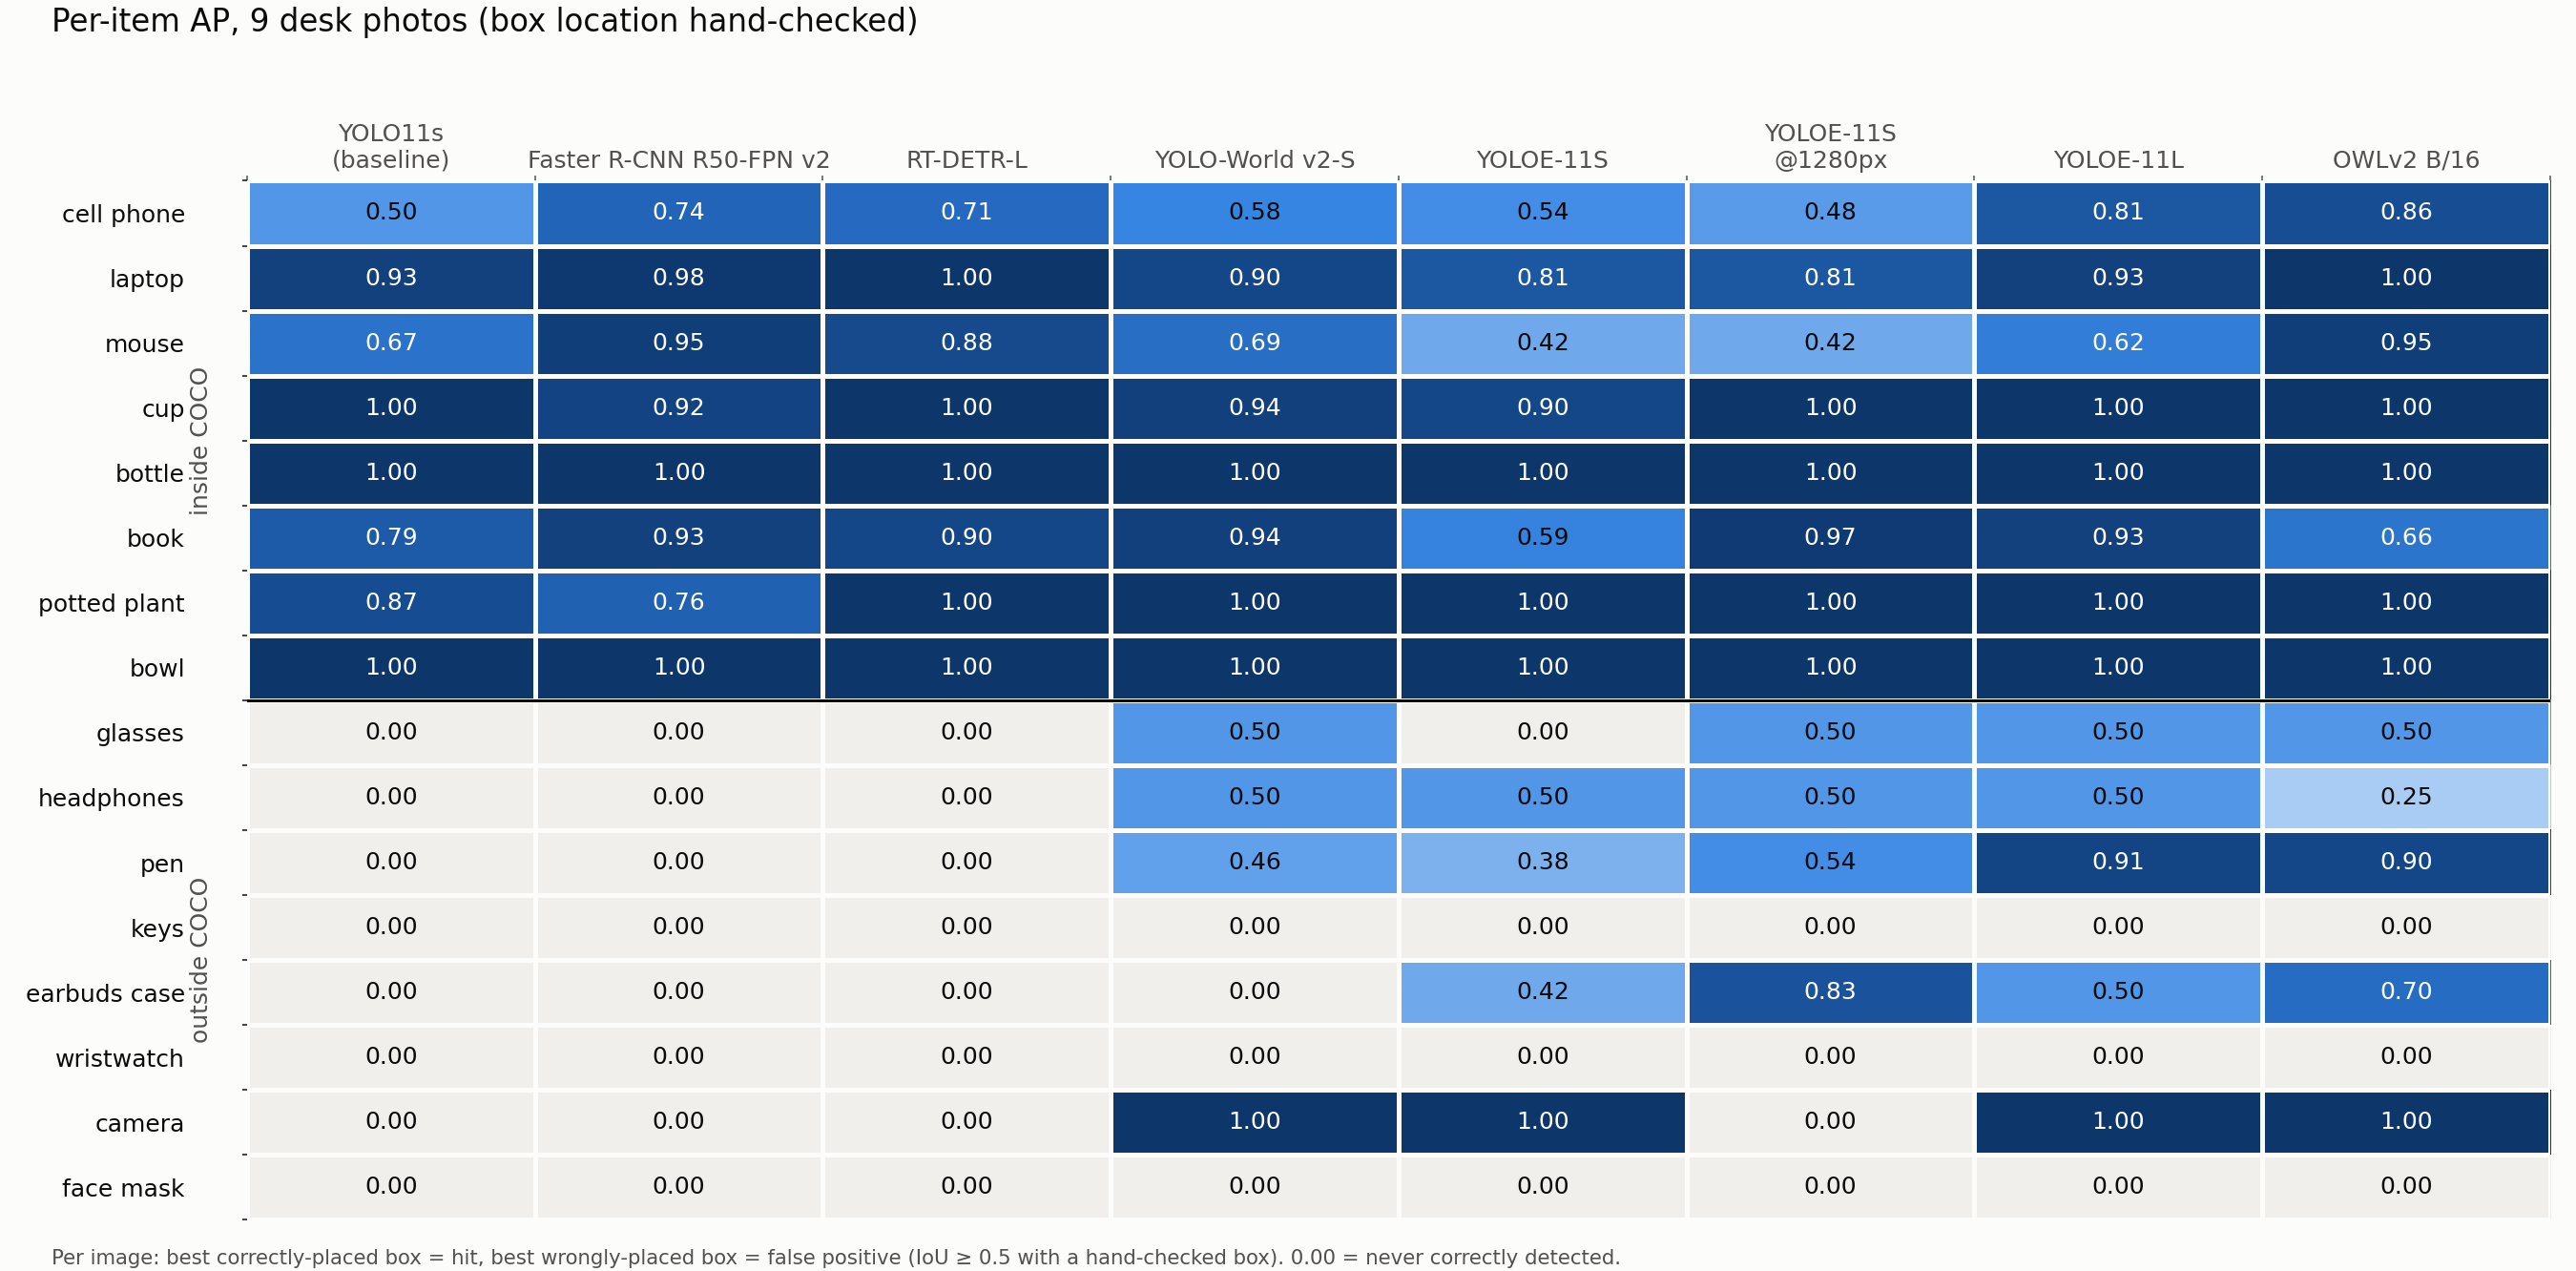

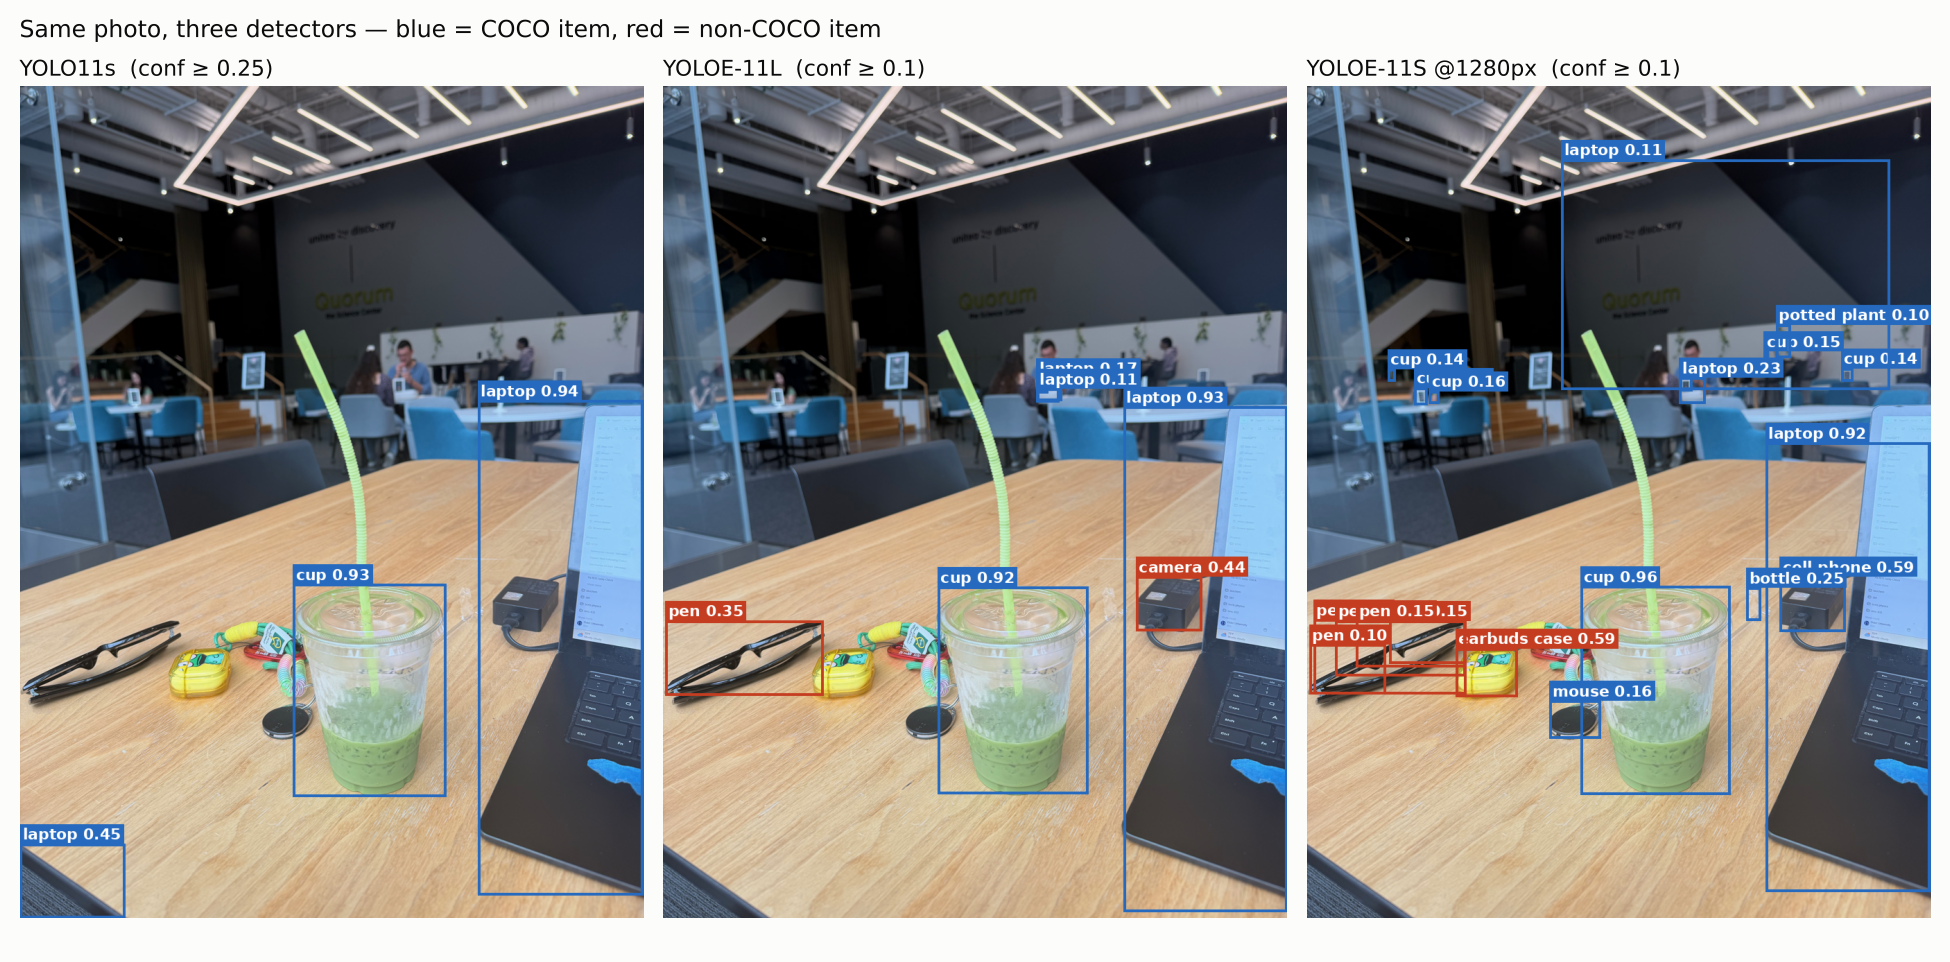

In [4]:
!python benchmark/make_figures.py
display(Image(filename="benchmark/results/per_item_ap_heatmap.png"))
display(Image(filename="benchmark/results/example_9jpg.png"))

## 4. Per-model detections (boxes above each model's default threshold)
Green = COCO item, red = non-COCO item.

1.jpg


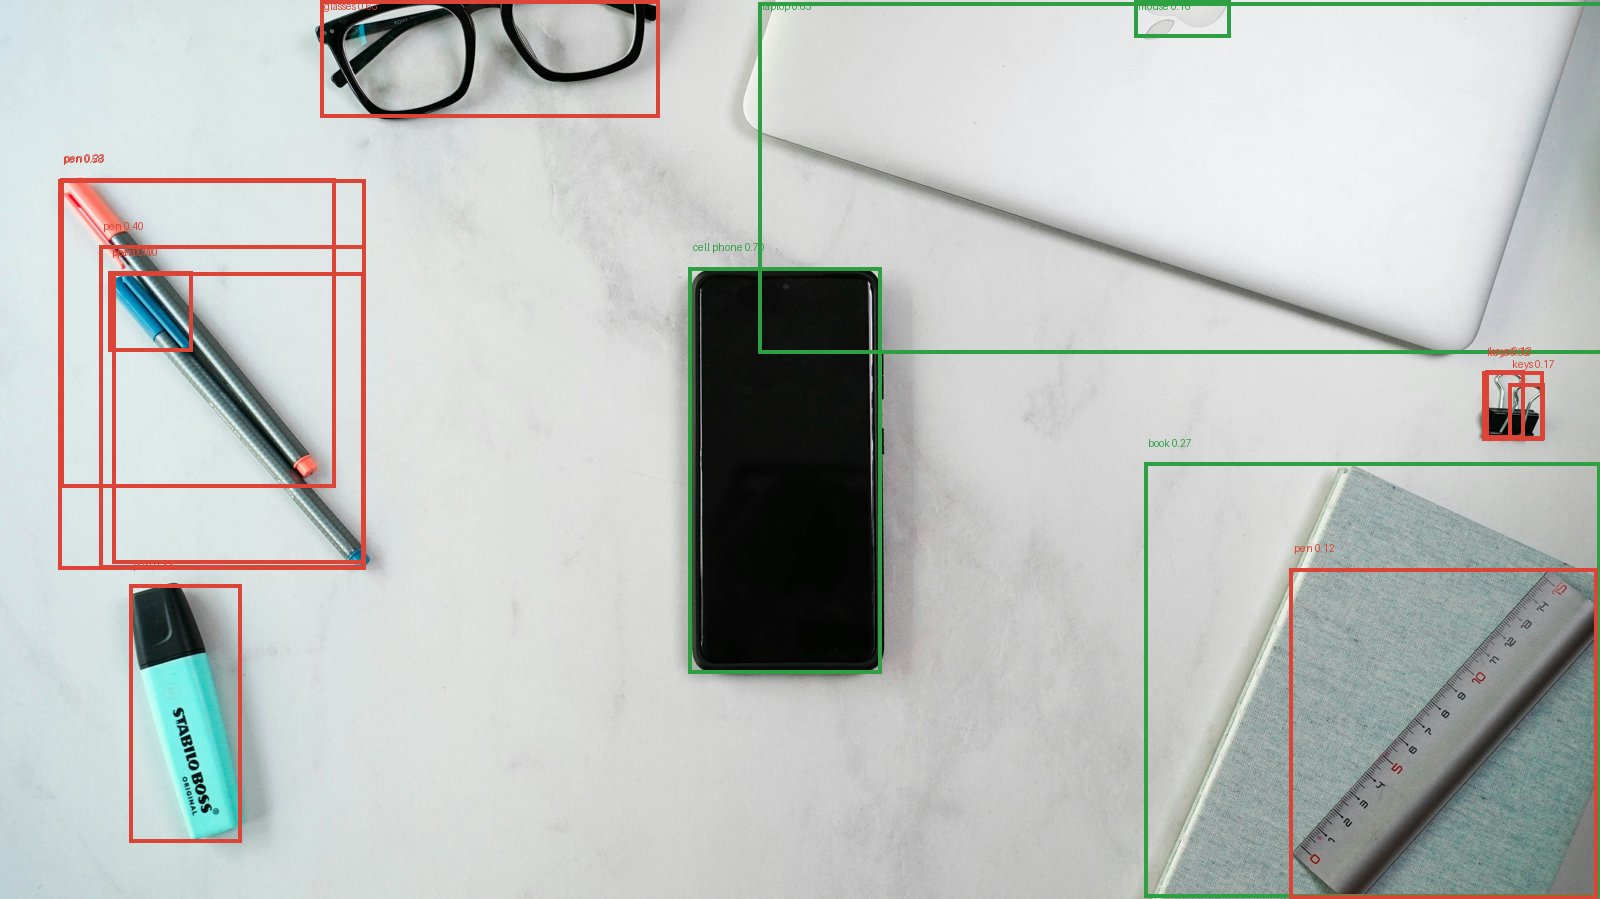

2.jpg


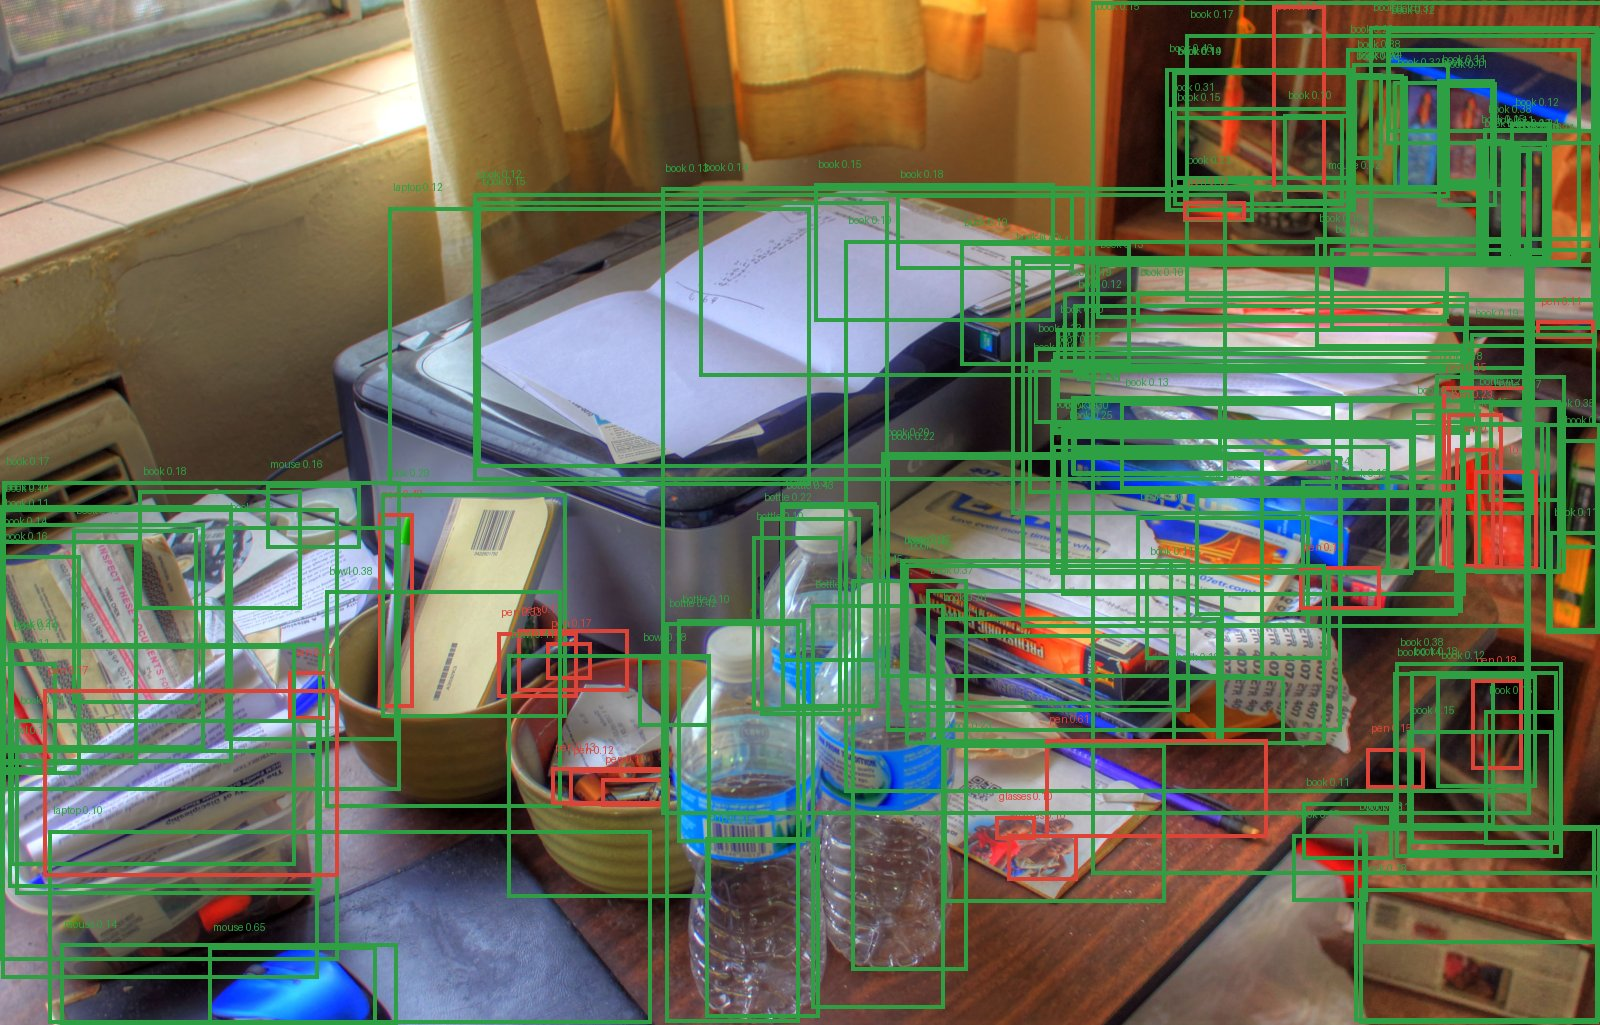

3.jpg


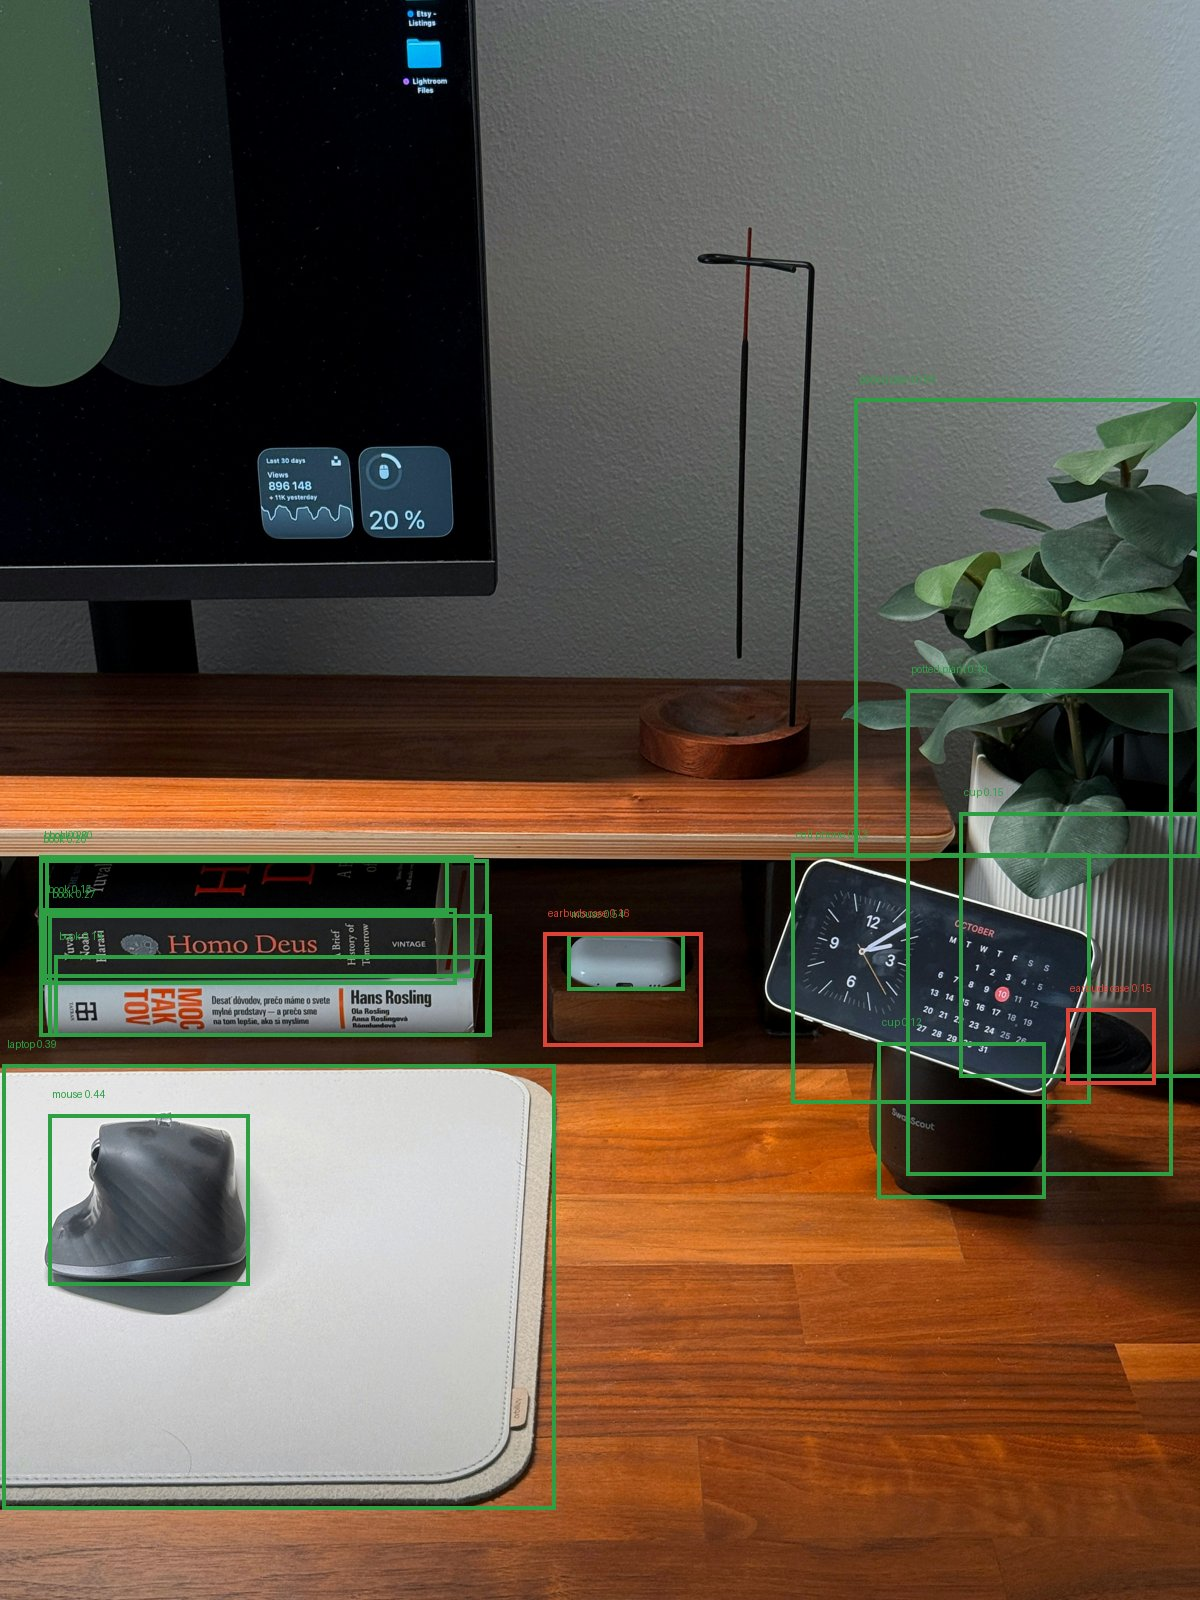

4.jpg


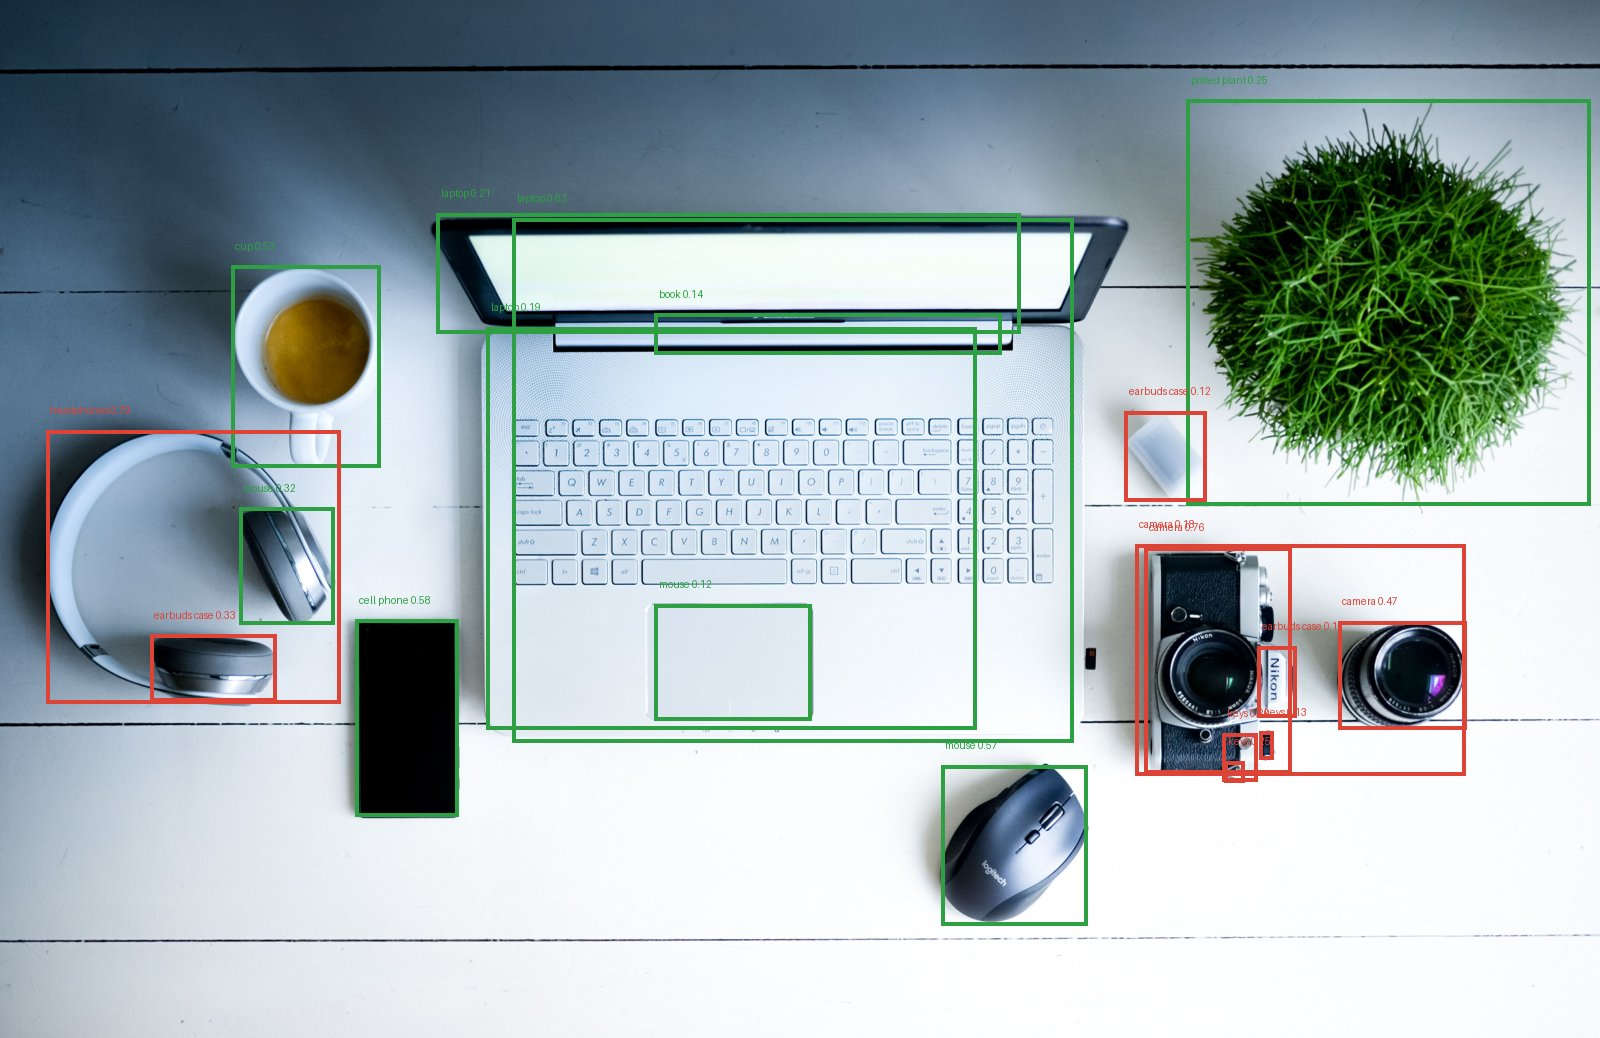

5.jpg


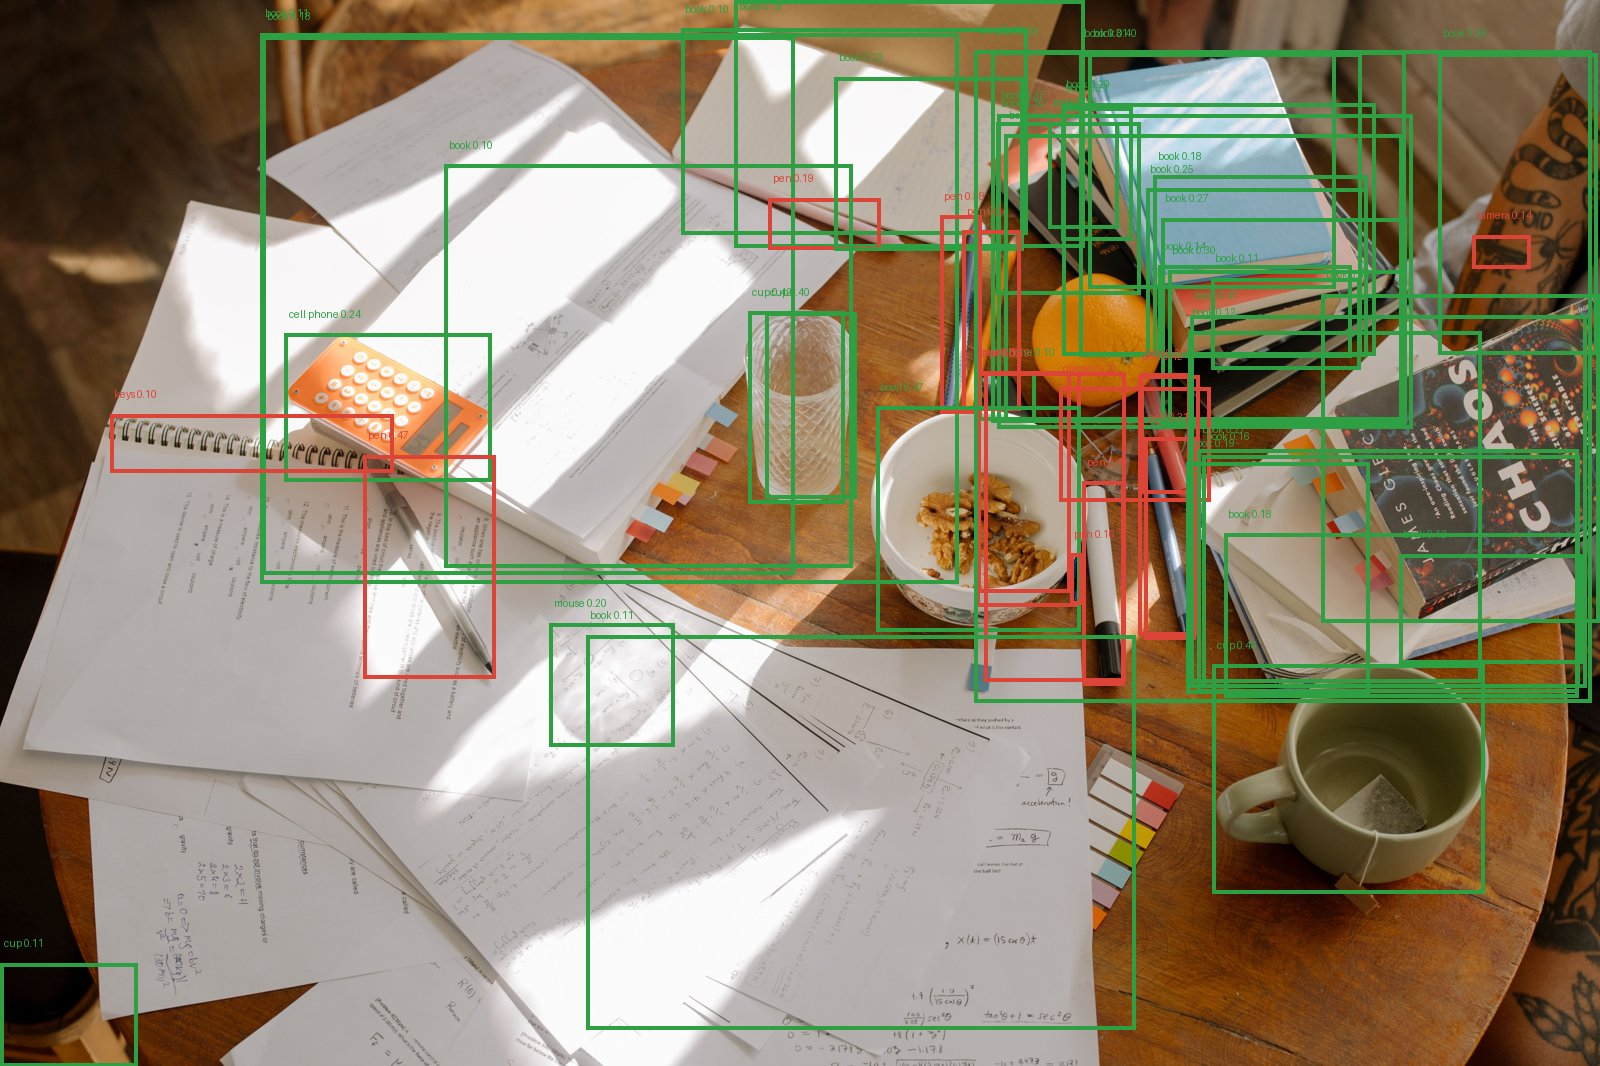

6.jpg


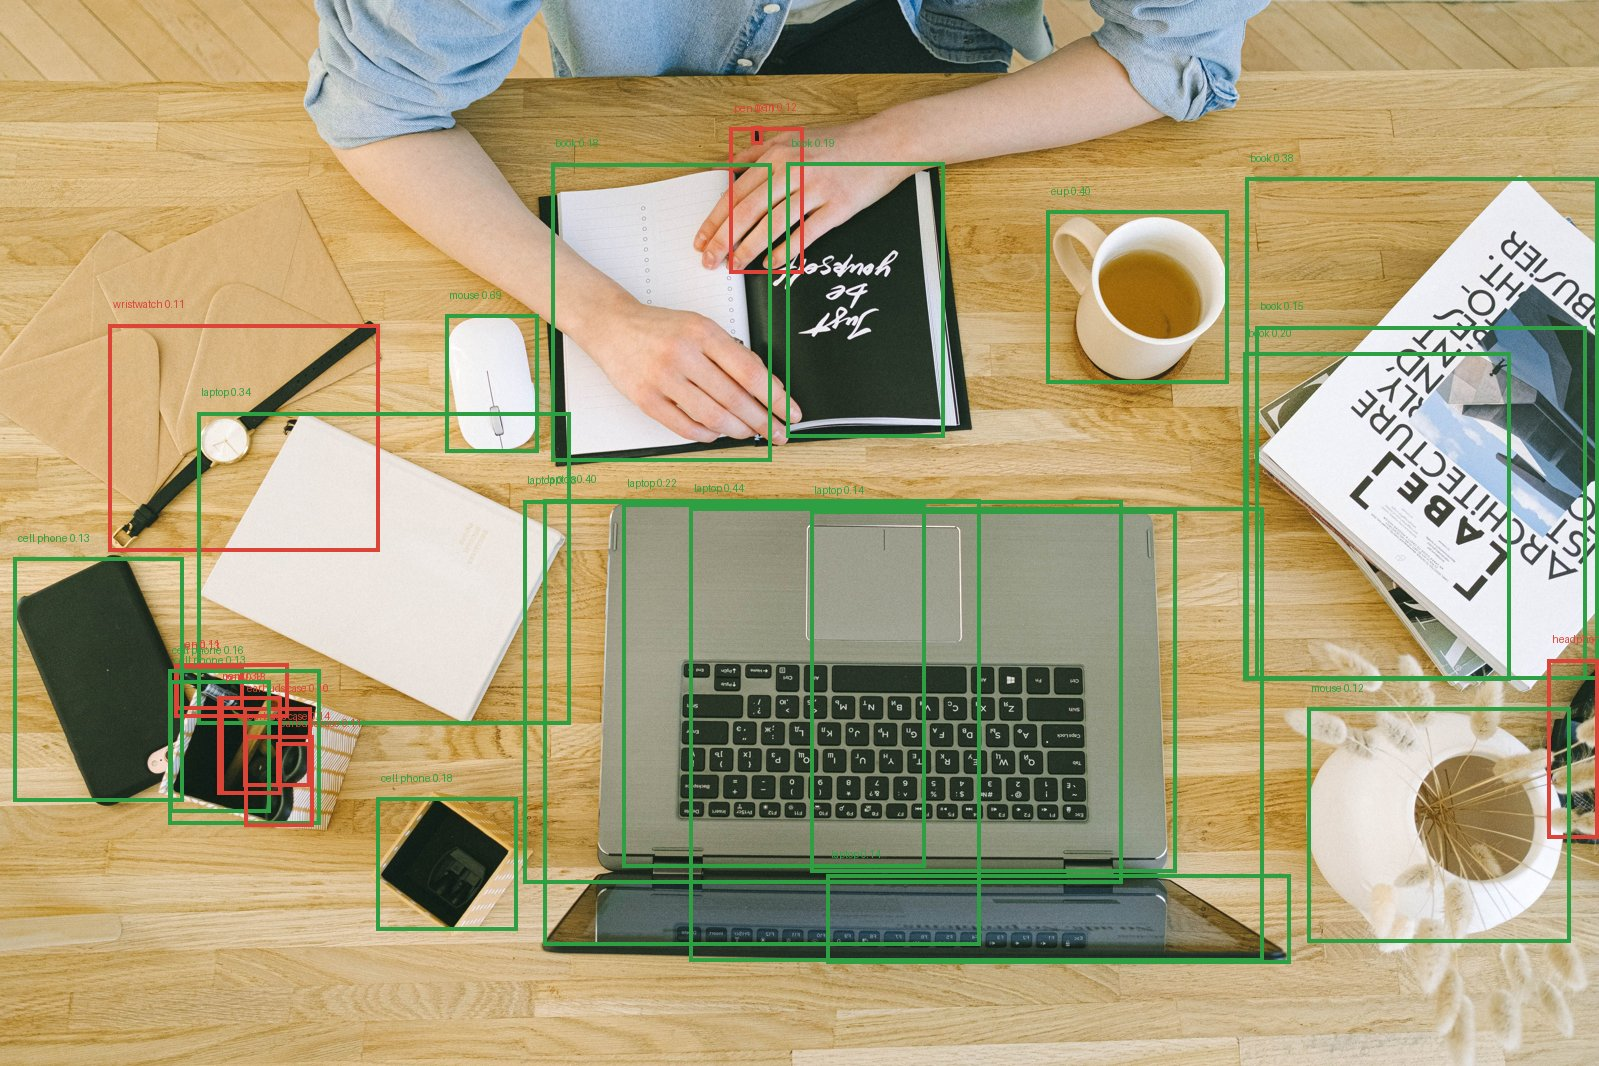

7.jpg


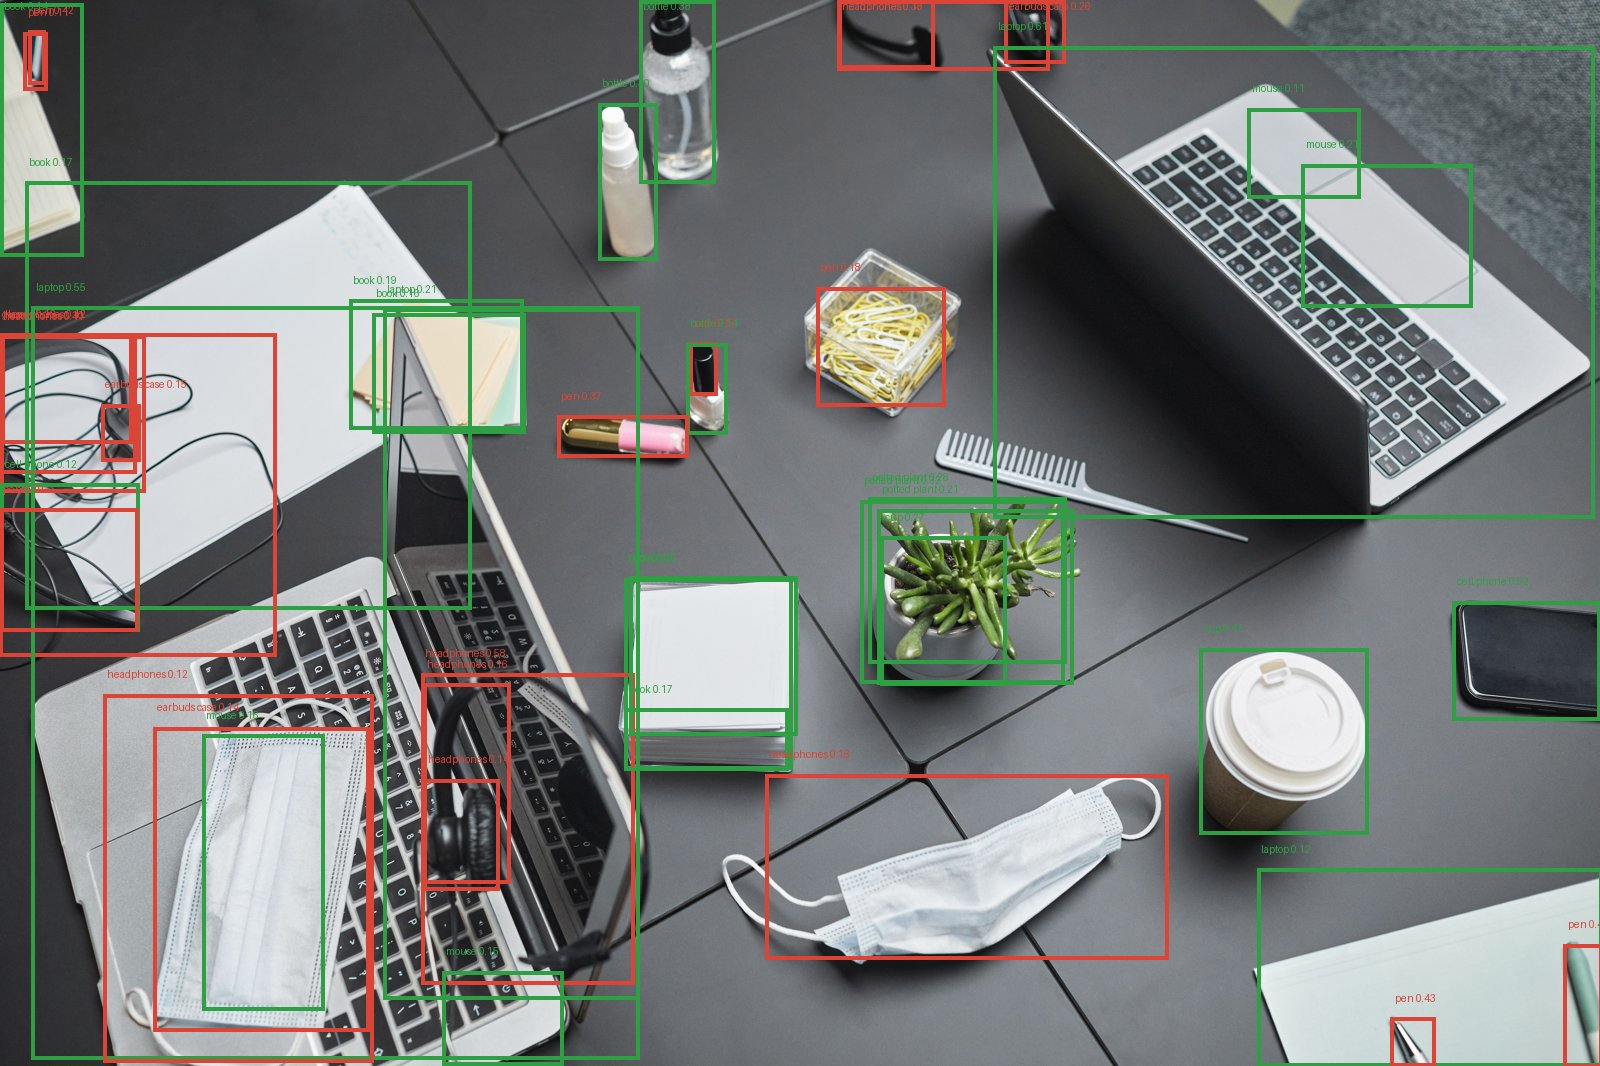

8.jpg


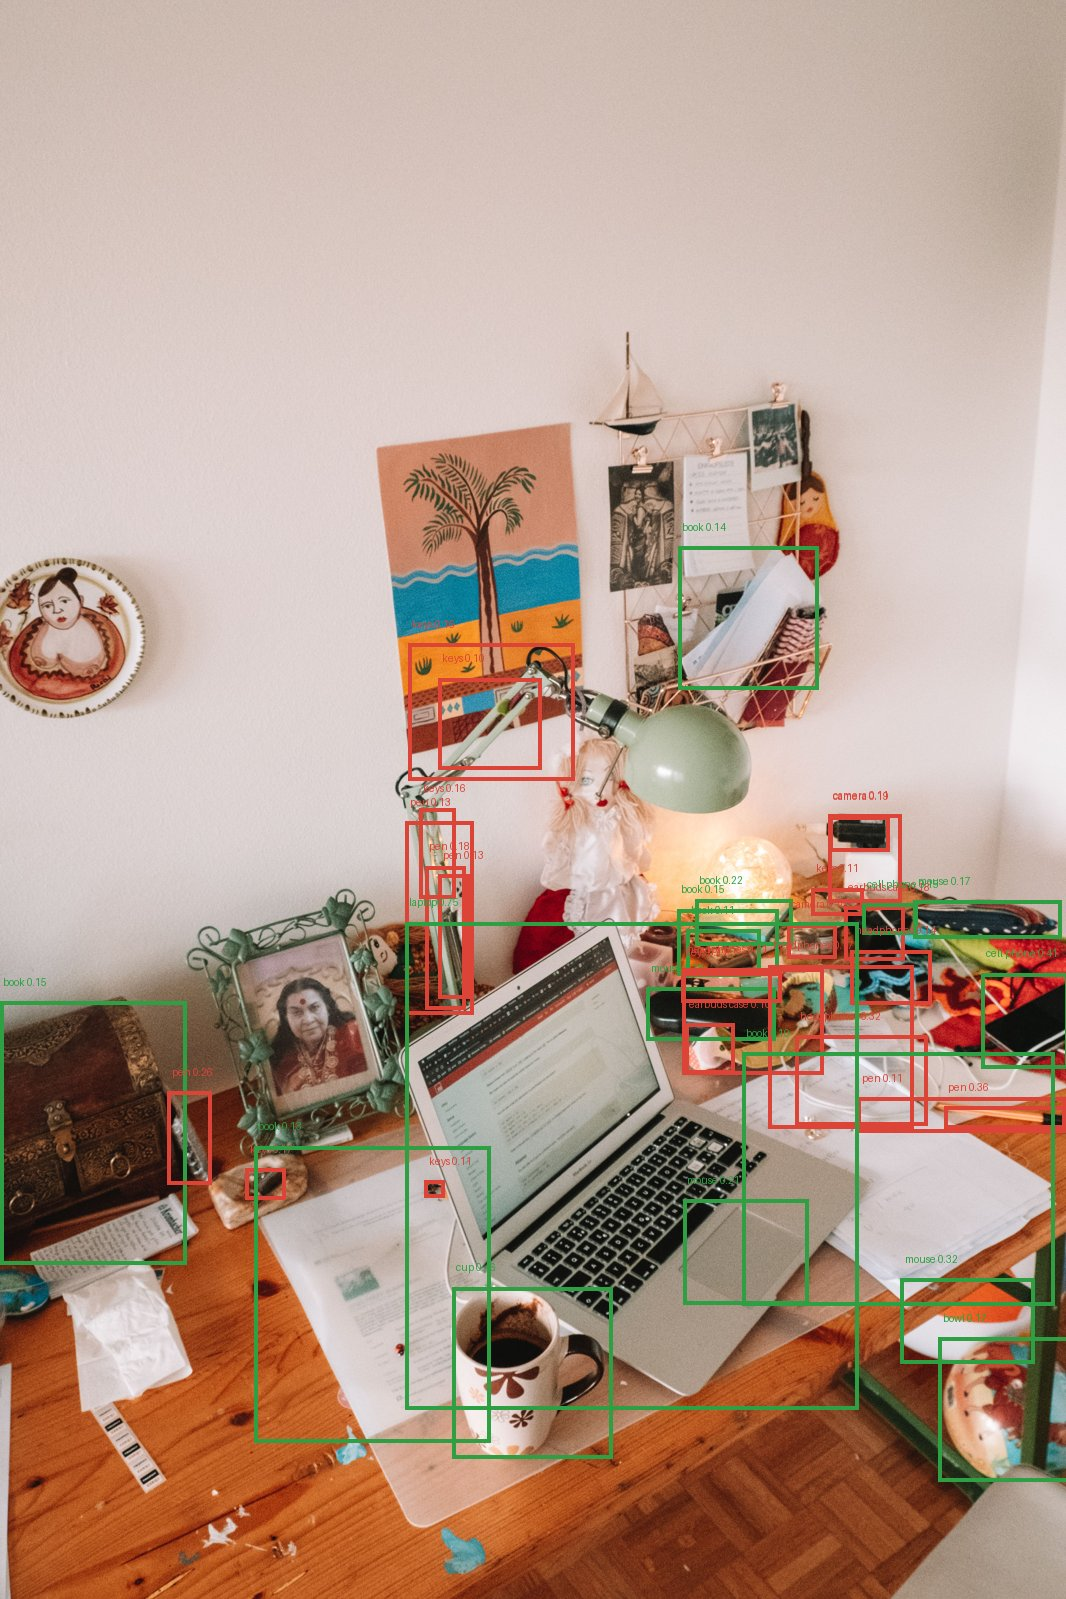

9.jpg


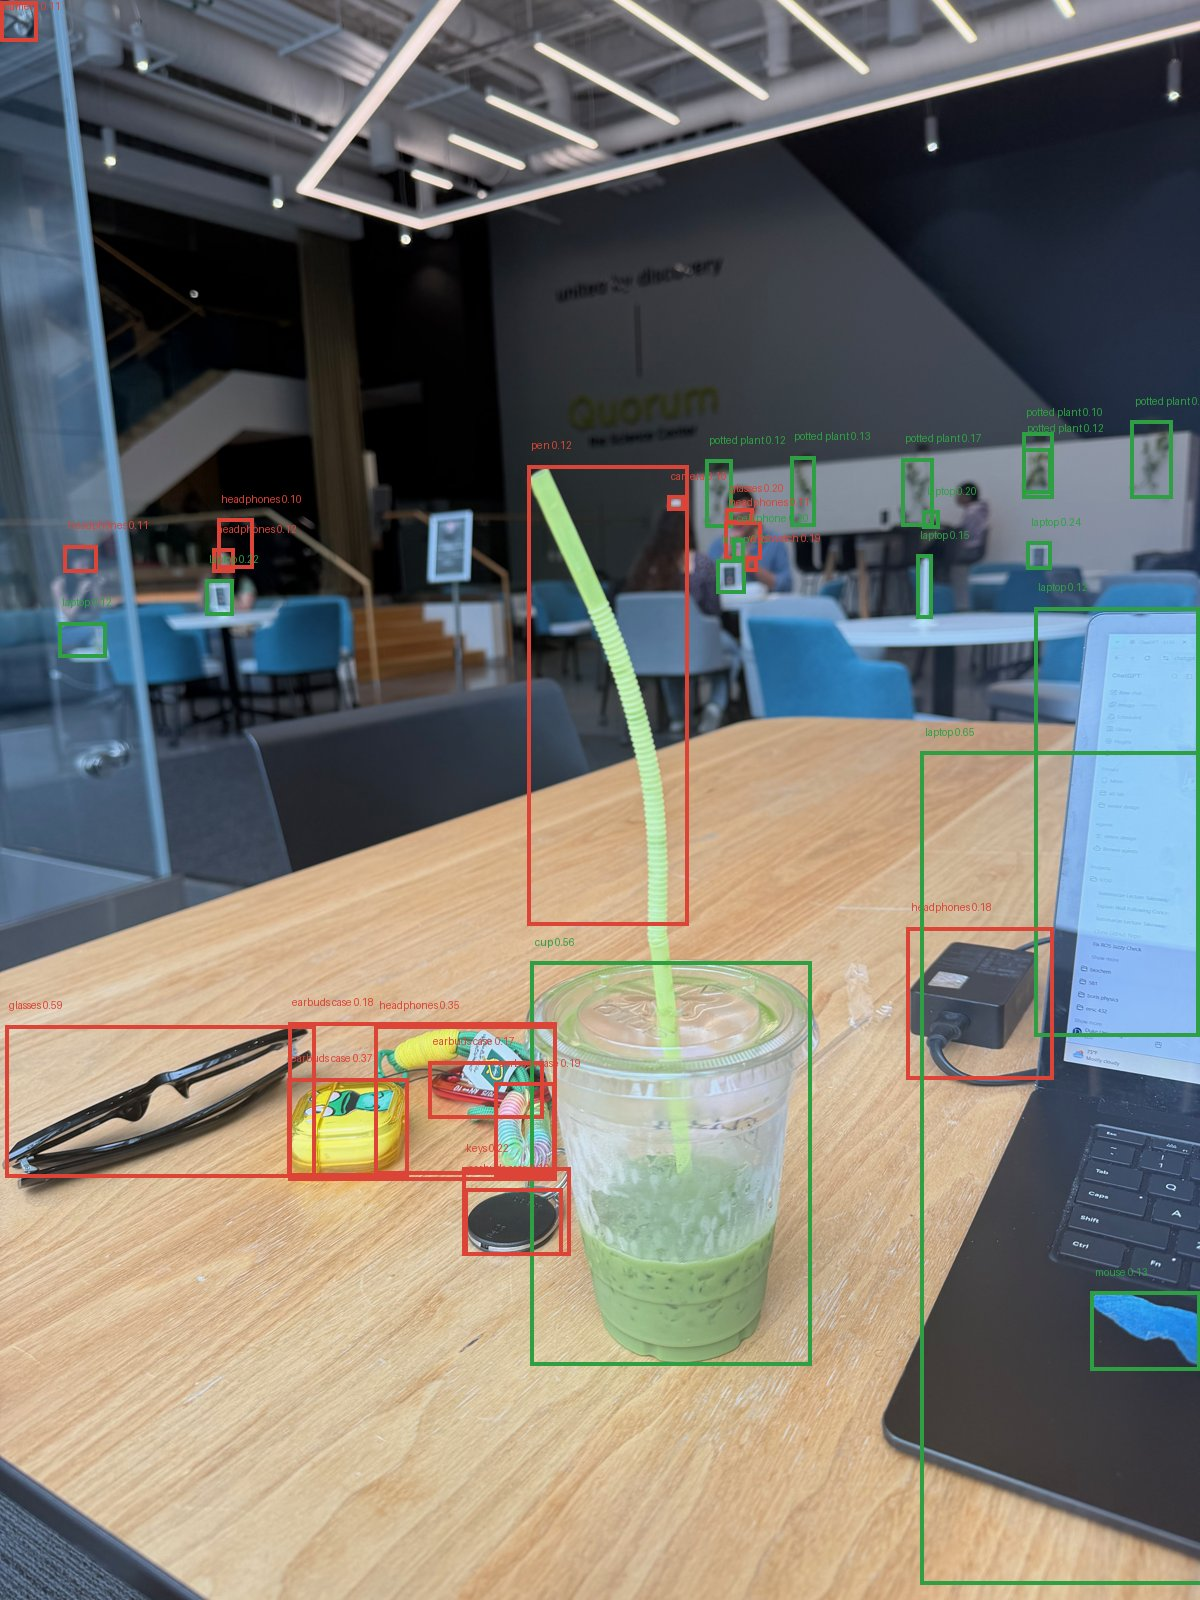

In [5]:
MODEL = "owlv2"   # any key from MODELS_TO_RUN
for name in sorted(os.listdir(f"benchmark/results/vis/{MODEL}")):
    print(name)
    display(Image(filename=f"benchmark/results/vis/{MODEL}/{name}", width=700))